# Alquiler — 05 Mejora del modelo final (breve)

**Modelo a mejorar:** el OLS Stepwise del notebook `04_Modelo_OLS.ipynb`, elegido allí por la regla de parsimonia del 1 % en test.

**Forma de mejora que se prueba en este notebook (definida antes de evaluar):**

El diagnóstico de `04` mostró error aproximadamente proporcional al nivel de precio, cola derecha pesada y compresión de los extremos. Por eso se prueba pasar de modelar el alquiler en niveles a modelarlo en logaritmos:

1. **Referencia (sin mejora):** OLS en niveles con el subconjunto Stepwise de `04`, reproducido acá desde train.
2. **OLS log:** OLS sobre `log(monthly_rent_rub)` con el mismo subconjunto. Para volver a rublos se aplica `exp(predicción) * factor de Duan`, donde el factor es el promedio de `exp(residuo en escala log)` calculado solo con los datos de ajuste de cada fold o del ajuste final. Sin ese factor, la retransformación subestimaría sistemáticamente el nivel.
3. **OLS log + polinomio:** el mismo modelo log más tres términos definidos a priori a partir de columnas existentes: `area_f_z` al cuadrado, `metro_f_z` al cuadrado y la interacción `area_f_z x metro_f_z`. Buscan capturar la no linealidad que comprime los extremos.

**Reglas de comparación (antes de mirar test):**

- El subconjunto Stepwise se reproduce solo con train, con el mismo forward stepwise por BIC de `04`.
- El candidato campeón se elige por **MAE walk-forward dentro de train (2022, 2023 y 2024)**, porque el diagnóstico indica error proporcional y cola pesada: el MAE en rublos mide el error típico y es menos dominado por el segmento premium que la target winsorizada de train apenas contiene. El RMSE walk-forward se reporta como control y cualquier tradeoff queda explícito.
- Todas las métricas se reportan en **rublos** sobre la target original: R2, RMSE y MAE, en validación temporal y en test.
- Test se usa solo para reportar al final. No elige candidato, términos ni correcciones. Como test ya se usó en `04` para elegir el modelo final, tampoco acá es una evaluación independiente; es una comparación exploratoria adicional.

## 1. Datos, split y reproducción del subconjunto Stepwise

Se conservan la target `monthly_rent_rub` en rublos, el split train 2021-2024 / test 2025-2026 y la matriz de 140 features de la etapa 03. El forward stepwise con BIC se replica sobre train con la misma aritmética de RSS de `04` para recuperar el subconjunto del modelo a mejorar, sin leer resultados de test.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_DIR = Path("..") / "data"
OUT_DIR = DATA_DIR / "processed"
TARGET = "monthly_rent_rub"

train = pd.read_csv(OUT_DIR / "rentals_train_fe.csv", parse_dates=["date_posted"])
test = pd.read_csv(OUT_DIR / "rentals_test_fe.csv", parse_dates=["date_posted"])
FEATURES_BASE = (["area_f_z", "metro_f_z", "furnished", "pets_allowed"]
                 + [c for c in train.columns if c.startswith("district_")]
                 + [c for c in train.columns if c.startswith("building_type_")]
                 + [c for c in train.columns if c.startswith("renovation_")])
assert len(FEATURES_BASE) == 140
assert all(c in test.columns for c in FEATURES_BASE)
assert train["date_posted"].max() < pd.Timestamp("2025-01-01") <= test["date_posted"].min()
print(f"train {len(train):,} (2021-2024) | test {len(test):,} (2025-2026) | p = {len(FEATURES_BASE)}")

def metricas(y_real, y_pred):
    y_real = np.asarray(y_real, float); y_pred = np.asarray(y_pred, float)
    return {"R2": float(r2_score(y_real, y_pred)),
            "RMSE_RUB": float(np.sqrt(mean_squared_error(y_real, y_pred))),
            "MAE_RUB": float(mean_absolute_error(y_real, y_pred))}

# Forward stepwise con BIC solo en train, replicando el procedimiento de 04.
Xg = np.column_stack([np.ones(len(train)), train[FEATURES_BASE].astype(float).to_numpy()])
yg = train[TARGET].astype(float).to_numpy()
XtX, Xty, yty = Xg.T @ Xg, Xg.T @ yg, float(yg @ yg)
pos = {c: i + 1 for i, c in enumerate(FEATURES_BASE)}
N_TR = len(train)

def rss_subconjunto(cols):
    idx = [0] + [pos[c] for c in cols]
    A = XtX[np.ix_(idx, idx)]; b = Xty[idx]
    try:
        beta = np.linalg.solve(A, b); rss = float(yty - b @ beta)
    except np.linalg.LinAlgError:
        beta = np.linalg.pinv(A) @ b; rss = float(yty - 2.0 * (b @ beta) + beta @ A @ beta)
    return max(rss, 0.0)

def bic_de(rss, k_cols):
    return N_TR * np.log(max(rss, 1e-9) / N_TR) + (k_cols + 1) * np.log(N_TR)

sel, restantes = [], list(FEATURES_BASE)
bic_actual = bic_de(rss_subconjunto([]), 0)
for _paso in range(140):
    mejor = None
    for c in restantes:
        bic_c = bic_de(rss_subconjunto(sel + [c]), len(sel) + 1)
        if mejor is None or bic_c < mejor[1]:
            mejor = (c, bic_c)
    if bic_actual - mejor[1] < 2.0:
        break
    sel.append(mejor[0]); restantes.remove(mejor[0]); bic_actual = mejor[1]
COLS_SWS = list(sel)
print(f"Subconjunto Stepwise reproducido solo con train: {len(COLS_SWS)} features")
print(", ".join(COLS_SWS))

train 14,820 (2021-2024) | test 4,841 (2025-2026) | p = 140


Subconjunto Stepwise reproducido solo con train: 109 features
metro_f_z, area_f_z, renovation_designer, district_Khamovniki, renovation_euro, district_Arbat, district_Tverskoy, district_Presnensky, district_Yakimanka, building_type_khrushchev, district_Zamoskvorechye, district_Dorogomilovo, district_Basmanny, district_Meshchansky, district_Krasnoselsky, district_Tagansky, district_Krylatskoye, district_Prospekt Vernadskogo, district_Lomonosovsky, district_Gagarinsky, district_Ramenki, building_type_stalin, building_type_monolith, building_type_brick, district_Filyovsky Park, district_Troparyovo-Nikulino, furnished, district_Kurkino, district_Akademichesky, district_Fili-Davydkovo, renovation_no_renovation, building_type_modern_panel, district_Khoroshyovsky, district_Cheryomushki, district_Shchapovskoye, district_Strogino, district_Shchukino, district_Sokol, district_Obruchevsky, district_Kuntsevo, district_Kotlovka, district_Begovoy, district_Mikhaylovo-Yartsevskoye, district_Krasnopak

## 2. Candidatos definidos antes de evaluar

Los tres candidatos usan exactamente el mismo subconjunto Stepwise y difieren solo en la forma funcional declarada arriba. El término polinómico no se busca mirando datos: son los cuadrados de las dos continuas y su interacción, definidos a priori. Ningún candidato usa test para construirse.

In [2]:
def diseno(df, cols, polinomio=False):
    X = df[list(cols)].astype(float).copy()
    if polinomio:
        X["area_f_z_sq"] = df["area_f_z"].astype(float) ** 2
        X["metro_f_z_sq"] = df["metro_f_z"].astype(float) ** 2
        X["area_x_metro"] = df["area_f_z"].astype(float) * df["metro_f_z"].astype(float)
    return X

def ajustar_predecir(tr, va, cols, log=False, polinomio=False):
    Xtr = sm.add_constant(diseno(tr, cols, polinomio), has_constant="add")
    Xva = sm.add_constant(diseno(va, cols, polinomio), has_constant="add")
    y = np.log(tr[TARGET].astype(float)) if log else tr[TARGET].astype(float)
    modelo = sm.OLS(y, Xtr).fit()
    pred = np.asarray(modelo.predict(Xva), float)
    if log:
        # Correccion de Duan: factor calculado solo con residuos del ajuste (tr), nunca con va.
        factor_duan = float(np.mean(np.exp(np.asarray(modelo.resid, float))))
        pred = np.exp(pred) * factor_duan
    return pred

CANDIDATOS = {
    "Referencia_niveles": {"log": False, "polinomio": False},
    "OLS_log": {"log": True, "polinomio": False},
    "OLS_log_polinomio": {"log": True, "polinomio": True},
}
for nombre, cfg in CANDIDATOS.items():
    print(f"{nombre}: log={cfg['log']}, polinomio={cfg['polinomio']}, features base={len(COLS_SWS)}")

Referencia_niveles: log=False, polinomio=False, features base=109
OLS_log: log=True, polinomio=False, features base=109
OLS_log_polinomio: log=True, polinomio=True, features base=109


## 3. Selección del campeón solo por validación temporal en train

Walk-forward 2022, 2023 y 2024: cada fold ajusta solo con el pasado, y en los modelos log el factor de Duan sale solo de ese pasado. El campeón es el de menor **MAE walk-forward medio**; el RMSE medio se muestra como control del tradeoff.

In [3]:
filas_wf = []
for nombre, cfg in CANDIDATOS.items():
    for anio in (2022, 2023, 2024):
        tr = train[train["date_posted"].dt.year < anio]
        va = train[train["date_posted"].dt.year == anio]
        pred = ajustar_predecir(tr, va, COLS_SWS, **cfg)
        filas_wf.append({"modelo": nombre, "validacion": anio, **metricas(va[TARGET], pred)})
tabla_wf = pd.DataFrame(filas_wf)
resumen_wf = (tabla_wf.groupby("modelo", as_index=False)
              .agg(R2_WF=("R2", "mean"), RMSE_WF=("RMSE_RUB", "mean"), MAE_WF=("MAE_RUB", "mean")))
resumen_wf = resumen_wf.sort_values("MAE_WF")
print("Validacion temporal dentro de train (promedio de folds 2022-2024, metricas en rublos)")
display(resumen_wf.round(2))
display(tabla_wf.round(2))
CAMPEON = str(resumen_wf.iloc[0]["modelo"])
_ref = resumen_wf.loc[resumen_wf["modelo"] == "Referencia_niveles"].iloc[0]
_cam = resumen_wf.iloc[0]
print(f"Campeon por MAE walk-forward: {CAMPEON} (MAE WF = {float(_cam['MAE_WF']):,.0f} RUB vs referencia {float(_ref['MAE_WF']):,.0f} RUB; "
      f"RMSE WF = {float(_cam['RMSE_WF']):,.0f} RUB vs referencia {float(_ref['RMSE_WF']):,.0f} RUB)")
if CAMPEON == "Referencia_niveles":
    print("Resultado: ningun candidato log supero a la referencia en MAE walk-forward; no se declara mejora.")
else:
    print(f"Resultado en train: {CAMPEON} mejora el MAE walk-forward de la referencia en {float(_ref['MAE_WF'] - _cam['MAE_WF']):,.0f} RUB "
          f"({float(100 * (_ref['MAE_WF'] - _cam['MAE_WF']) / _ref['MAE_WF']):.1f}%). El contraste de RMSE WF queda en la tabla como control.")

Validacion temporal dentro de train (promedio de folds 2022-2024, metricas en rublos)


,modelo,R2_WF,RMSE_WF,MAE_WF
1,OLS_log_polinomio,0.87,8990.60,6224.77
0,OLS_log,0.86,9366.98,6399.91
2,Referencia_niveles,0.87,8809.83,6696.87


,modelo,validacion,R2,RMSE_RUB,MAE_RUB
0,Referencia_niveles,2022,0.90,7661.58,5734.11
1,Referencia_niveles,2023,0.86,9189.68,7045.72
2,Referencia_niveles,2024,0.86,9578.22,7310.77
3,OLS_log,2022,0.88,8067.46,5087.27
4,OLS_log,2023,0.85,9619.51,6803.72
5,OLS_log,2024,0.84,10413.98,7308.75
6,OLS_log_polinomio,2022,0.89,7714.44,4893.57
7,OLS_log_polinomio,2023,0.86,9228.69,6647.83
8,OLS_log_polinomio,2024,0.85,10028.66,7132.90


Campeon por MAE walk-forward: OLS_log_polinomio (MAE WF = 6,225 RUB vs referencia 6,697 RUB; RMSE WF = 8,991 RUB vs referencia 8,810 RUB)
Resultado en train: OLS_log_polinomio mejora el MAE walk-forward de la referencia en 472 RUB (7.0%). El contraste de RMSE WF queda en la tabla como control.


## 4. Reporte en test (no usado para elegir)

Con el campeón ya cerrado por validación temporal, se ajusta cada candidato en todo train y se reporta test una sola vez. Estas cifras no eligieron nada y, como test ya participó en la elección del modelo final de `04`, deben leerse como comparación exploratoria, no como evaluación independiente.

Ajuste en todo train y reporte en test (test no eligio candidato)


,modelo,R2_train,RMSE_RUB_train,MAE_RUB_train,R2_test,RMSE_RUB_test,MAE_RUB_test,R2_WF,RMSE_WF,MAE_WF
0,Referencia_niveles,0.90,7933.87,6170.92,0.81,13653.18,7802.50,0.87,8809.83,6696.87
1,OLS_log,0.88,8523.36,5575.35,0.88,10599.08,6491.83,0.86,9366.98,6399.91
2,OLS_log_polinomio,0.89,8052.06,5352.70,0.89,10560.75,6384.14,0.87,8990.60,6224.77


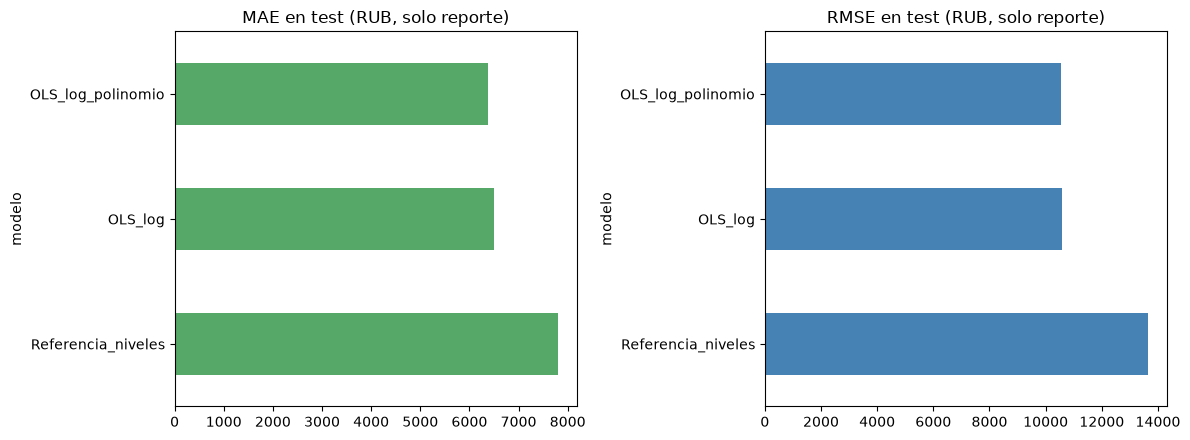

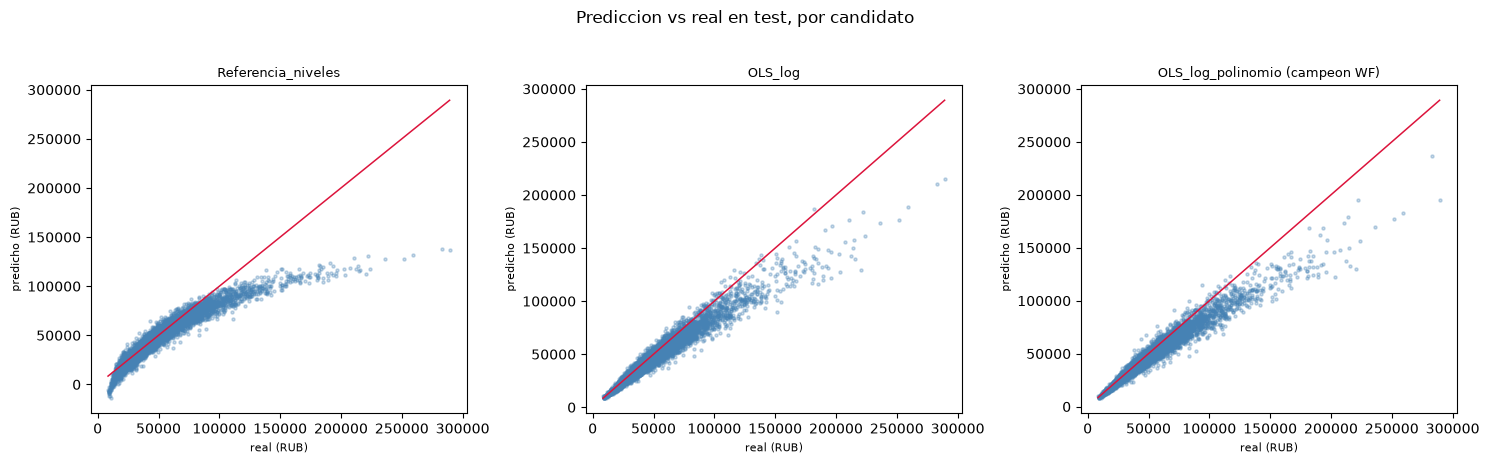

Lectura dinamica: el campeon por validacion temporal fue OLS_log_polinomio. En el reporte de test, su MAE fue 6,384 RUB frente a 7,803 RUB de la referencia, y su RMSE 10,561 RUB frente a 13,653 RUB. Estas diferencias de test son descriptivas: no participaron en la eleccion del campeon.


In [4]:
filas_test = []
preds_test = {}
for nombre, cfg in CANDIDATOS.items():
    pred_tr = ajustar_predecir(train, train, COLS_SWS, **cfg)
    pred_te = ajustar_predecir(train, test, COLS_SWS, **cfg)
    preds_test[nombre] = pred_te
    filas_test.append({"modelo": nombre,
                       **{f"{k}_train": v for k, v in metricas(train[TARGET], pred_tr).items()},
                       **{f"{k}_test": v for k, v in metricas(test[TARGET], pred_te).items()}})
tabla_test = pd.DataFrame(filas_test)
# Agregar la validacion temporal ya calculada para una lectura en un solo lugar.
tabla_test = tabla_test.merge(resumen_wf, on="modelo", how="left")
print("Ajuste en todo train y reporte en test (test no eligio candidato)")
display(tabla_test.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
orden = tabla_test.sort_values("MAE_RUB_test")
orden.set_index("modelo")["MAE_RUB_test"].plot.barh(ax=axes[0], color="#55A868")
axes[0].set_title("MAE en test (RUB, solo reporte)"); axes[0].invert_yaxis()
orden.set_index("modelo")["RMSE_RUB_test"].plot.barh(ax=axes[1], color="steelblue")
axes[1].set_title("RMSE en test (RUB, solo reporte)"); axes[1].invert_yaxis()
plt.tight_layout(); plt.show()

fig2, axes2 = plt.subplots(1, len(CANDIDATOS), figsize=(15, 4.5), squeeze=False)
for ax, nombre in zip(axes2.ravel(), CANDIDATOS):
    ax.scatter(test[TARGET], preds_test[nombre], s=5, alpha=0.3, color="steelblue")
    lim = [float(test[TARGET].min()), float(test[TARGET].max())]
    ax.plot(lim, lim, color="crimson", lw=1.1)
    marca = " (campeon WF)" if nombre == CAMPEON else ""
    ax.set_title(f"{nombre}{marca}", fontsize=9)
    ax.set_xlabel("real (RUB)", fontsize=8); ax.set_ylabel("predicho (RUB)", fontsize=8)
fig2.suptitle("Prediccion vs real en test, por candidato", y=1.02)
plt.tight_layout(); plt.show()

_fila_campeon_test = tabla_test.loc[tabla_test["modelo"] == CAMPEON].iloc[0]
_fila_ref_test = tabla_test.loc[tabla_test["modelo"] == "Referencia_niveles"].iloc[0]
print(f"Lectura dinamica: el campeon por validacion temporal fue {CAMPEON}. En el reporte de test, su MAE fue "
      f"{float(_fila_campeon_test['MAE_RUB_test']):,.0f} RUB frente a {float(_fila_ref_test['MAE_RUB_test']):,.0f} RUB de la referencia, "
      f"y su RMSE {float(_fila_campeon_test['RMSE_RUB_test']):,.0f} RUB frente a {float(_fila_ref_test['RMSE_RUB_test']):,.0f} RUB. "
      "Estas diferencias de test son descriptivas: no participaron en la eleccion del campeon.")

## 5. Cierre

Este notebook probó una sola idea de mejora, definida antes de evaluar: modelar el logaritmo del alquiler con corrección de Duan al volver a rublos, con y sin términos cuadráticos e interacción de las dos continuas, sobre el mismo subconjunto Stepwise del modelo final de `04`.

La conclusión válida es la de la validación temporal de la sección 3: si el campeón log mejoró el MAE walk-forward, la mejora está apoyada en train; lo que se ve en test en la sección 4 es un reporte posterior y reutilizado, no una confirmación independiente. Si el campeón hubiera sido la referencia, la conclusión sería que esta idea no mejora el modelo en el criterio predefinido.

Queda fuera de este intento breve, como posible paso siguiente no evaluado acá: probar los mismos términos polinómicos en el modelo en niveles, o una tendencia temporal explícita. Ninguno de esos candidatos se ajustó ni se comparó en este notebook, y este intento no se registró como modelo final en MLflow.